# Task 1

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.model_selection import KFold, cross_val_score
from sklearn.utils import shuffle
from sklearn import metrics

In [ ]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
file_path = "/content/drive/My Drive/Colab Notebooks/Daily_Water_Intake.csv"
df = pd.read_csv(file_path)

print(df)

       Age  Gender  Weight (kg)  Daily Water Intake (liters)  \
0       56    Male           96                         4.23   
1       60    Male          105                         3.95   
2       36    Male           68                         2.39   
3       19  Female           74                         3.13   
4       38    Male           77                         2.11   
...    ...     ...          ...                          ...   
29995   47    Male           97                         3.45   
29996   49  Female          109                         5.32   
29997   56  Female           54                         1.50   
29998   36    Male          106                         4.00   
29999   26  Female           98                         4.43   

      Physical Activity Level Weather Hydration Level  
0                    Moderate     Hot            Good  
1                        High  Normal            Good  
2                    Moderate    Cold            Good  
3      

# Task 2

In [ ]:
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')
df['Weight (kg)'] = pd.to_numeric(df['Weight (kg)'], errors='coerce')
df['Daily Water Intake (liters)'] = pd.to_numeric(df['Daily Water Intake (liters)'], errors='coerce')

df.fillna({ 'Age': df['Age'].median() }, inplace=True)
df.fillna({ 'Weight (kg)': df['Weight (kg)'].median() }, inplace=True)
df.fillna({ 'Daily Water Intake (liters)': df['Daily Water Intake (liters)'].median() }, inplace=True)

df.fillna({ 'Gender': df['Gender'].mode()[0]}, inplace=True)
df.fillna({ 'Physical Activity Level': df['Physical Activity Level'].mode()[0] }, inplace=True)
df.fillna({ 'Weather': df['Weather'].mode()[0] }, inplace=True)
df.fillna({ 'Hydration Level': df['Hydration Level'].mode()[0] }, inplace=True)

df.drop_duplicates(inplace = True)

print(df)

       Age  Gender  Weight (kg)  Daily Water Intake (liters)  \
0       56    Male           96                         4.23   
1       60    Male          105                         3.95   
2       36    Male           68                         2.39   
3       19  Female           74                         3.13   
4       38    Male           77                         2.11   
...    ...     ...          ...                          ...   
29995   47    Male           97                         3.45   
29996   49  Female          109                         5.32   
29997   56  Female           54                         1.50   
29998   36    Male          106                         4.00   
29999   26  Female           98                         4.43   

      Physical Activity Level Weather Hydration Level  
0                    Moderate     Hot            Good  
1                        High  Normal            Good  
2                    Moderate    Cold            Good  
3      

# Task 3

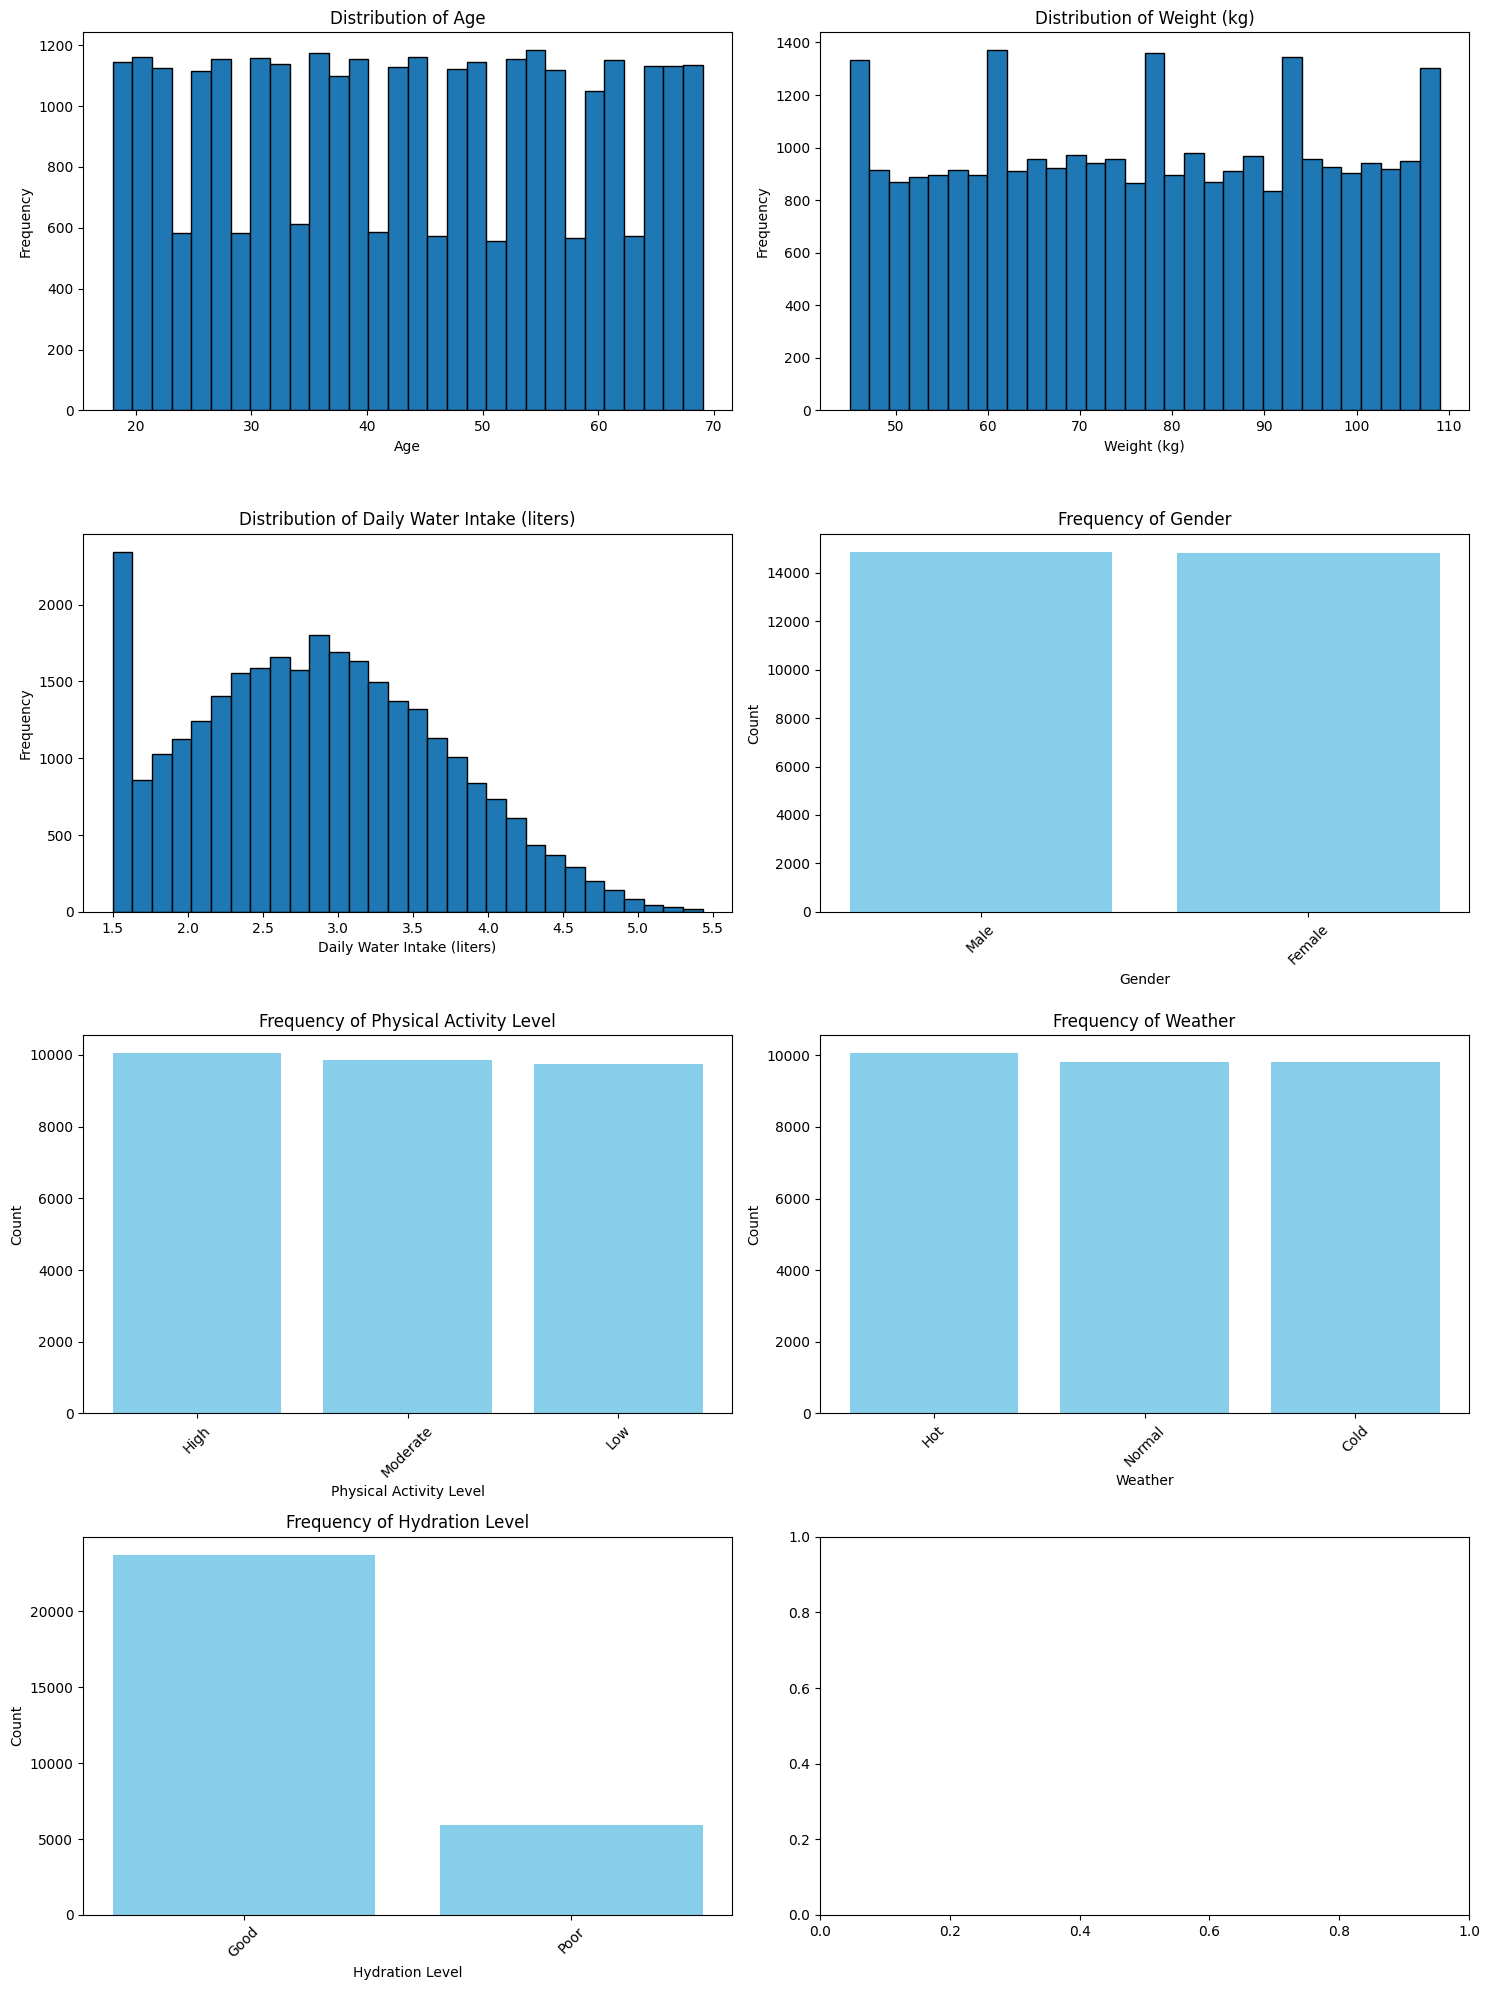

In [ ]:
numerical_cols = ['Age', 'Weight (kg)', 'Daily Water Intake (liters)']
categorical_cols = ['Gender', 'Physical Activity Level', 'Weather', 'Hydration Level']

fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(15, 20))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    axes[i].hist(df[col], bins=30, edgecolor='black')
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')

for i, col in enumerate(categorical_cols):
    counts = df[col].value_counts()
    axes[len(numerical_cols) + i].bar(counts.index, counts.values, color='skyblue')
    axes[len(numerical_cols) + i].set_title(f'Frequency of {col}')
    axes[len(numerical_cols) + i].set_xlabel(col)
    axes[len(numerical_cols) + i].set_ylabel('Count')
    axes[len(numerical_cols) + i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

#Task 4


In [ ]:
df['Gender'] = (
    df['Gender']
    .replace({'Male': 0, 'Female': 1})
    .infer_objects(copy=False)
)

df['Physical Activity Level'] = (
    df['Physical Activity Level']
    .replace({'Low': 0, 'Moderate': 1, 'High': 2})
    .infer_objects(copy=False)
)

df['Weather'] = (
    df['Weather']
    .replace({'Hot': 0, 'Normal': 1, 'Cold': 2})
    .infer_objects(copy=False)
)

df = shuffle(df)
X = df.drop('Hydration Level', axis=1)
y = df['Hydration Level']

scale = StandardScaler()
scaledX = scale.fit_transform(X)

print(X.shape)
print(scaledX.shape)

(29662, 6)
(29662, 6)


/tmp/ipython-input-2279680256.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .replace({'Male': 0, 'Female': 1})
/tmp/ipython-input-2279680256.py:9: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .replace({'Low': 0, 'Moderate': 1, 'High': 2})
/tmp/ipython-input-2279680256.py:15: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silen

#Task 5



In [ ]:
X_train, X_test, y_train, y_test = train_test_split(scaledX, y, test_size=0.2, random_state=3327)

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)


(23729, 6) (5933, 6) (23729,) (5933,)


#Task 6



In [ ]:
model = SVC()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(y_pred[:10])
print(y_test[:10])

['Poor' 'Good' 'Good' 'Poor' 'Good' 'Good' 'Good' 'Good' 'Good' 'Good']
10342    Poor
25204    Good
9186     Good
15379    Poor
10255    Good
3126     Good
28633    Good
4205     Good
10457    Good
7335     Good
Name: Hydration Level, dtype: object


#Task 7



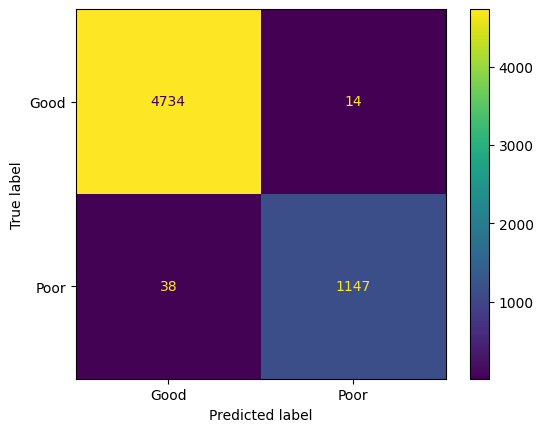

In [ ]:
confusion_matrix = metrics.confusion_matrix(y_test, y_pred)

cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix,
                                            display_labels = model.classes_)

cm_display.plot()
plt.show()

# Task 8


In [ ]:
train_accuracy = model.score(X_train, y_train)
test_accuracy = model.score(X_test, y_test)

print("Training Accuracy:", train_accuracy)
print("Test Accuracy:", test_accuracy)

if train_accuracy > test_accuracy:
    print("Training accuracy is higher than test accuracy")
elif train_accuracy < test_accuracy:
    print("Test accuracy is higher than training accuracy")
else:
    print("Training and test accuracy are equal")



Training Accuracy: 0.9918243499515361
Test Accuracy: 0.9912354626664419
Training accuracy is higher than test accuracy


# Task 9

In [ ]:
k_folds = KFold(n_splits = 10)
scores = cross_val_score(SVC(), scaledX, y, cv=k_folds)

print(scores)
print(np.mean(scores))
print(test_accuracy)


[0.99056286 0.98887765 0.98988537 0.99022252 0.98954821 0.99291976
 0.99190829 0.99291976 0.99325691 0.99426837]
0.9914369709874477
0.9912354626664419
